In [1]:

# ==========================================
# PHASE 6: BUSINESS INSIGHTS
# ==========================================

import pandas as pd
import numpy as np

from pathlib import Path
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
from getpass import getpass

# Load the final patient adherence results

output_path = Path("../outputs")

patient_adherence = pd.read_csv(
    output_path / "patient_adherence.csv"
)

print("Patient adherence data loaded successfully!")
print("Patient-measure groups:", len(patient_adherence))


Patient adherence data loaded successfully!
Patient-measure groups: 3565


In [2]:

# Connect to our MySQL database

db_password = getpass("Enter your MySQL password: ")

connection_url = URL.create(
    drivername="mysql+mysqlconnector",
    username="root",
    password=db_password,
    host="localhost",
    port=3306,
    database="medication_adherence"
)

engine = create_engine(
    connection_url,
    pool_pre_ping=True
)

with engine.connect() as connection:

    result = connection.execute(
        text("SELECT DATABASE()")
    ).scalar()

    print("MySQL connection successful!")
    print("Database:", result)


Enter your MySQL password:  ········


MySQL connection successful!
Database: medication_adherence


In [3]:

# Retrieve pharmacy channel and days supply using SQL

channel_data = pd.read_sql_query(
    """
    SELECT
        e.fill_id,
        e.patient_id,
        e.measure,
        e.fill_channel,
        e.days_supply

    FROM eligible_prescriptions AS e

    INNER JOIN patient_measure_cohort AS c

        ON e.patient_id = c.patient_id
        AND e.measure = c.measure
    """,
    con=engine
)

print("Pharmacy channel data loaded successfully!")
print("Eligible refill records:", len(channel_data))

print(
    "Unique patient-measure groups:",
    channel_data.groupby(
        ["patient_id", "measure"]
    ).ngroups
)


Pharmacy channel data loaded successfully!
Eligible refill records: 24640
Unique patient-measure groups: 3565


In [4]:

# ==========================================
# CLASSIFY PATIENTS BY PHARMACY CHANNEL
# ==========================================

# Aggregate days supply by patient, measure and channel

channel_supply = (
    channel_data
    .groupby(
        ["patient_id", "measure", "fill_channel"],
        as_index=False
    )
    .agg(
        total_days_supply=("days_supply", "sum")
    )
)

# Convert channel categories into separate columns

channel_pivot = channel_supply.pivot_table(
    index=["patient_id", "measure"],
    columns="fill_channel",
    values="total_days_supply",
    aggfunc="sum",
    fill_value=0
)

# Ensure both expected channel columns exist

channel_pivot = channel_pivot.reindex(
    columns=["mail_order", "retail"],
    fill_value=0
)

# Classify each patient-measure group

channel_pivot["dominant_channel"] = np.select(
    [
        channel_pivot["mail_order"] > channel_pivot["retail"],
        channel_pivot["retail"] > channel_pivot["mail_order"]
    ],
    [
        "Mail Order",
        "Retail"
    ],
    default="Mixed"
)

# Convert the result into a DataFrame

channel_classification = channel_pivot.reset_index()

print("PHARMACY CHANNEL CLASSIFICATION COMPLETED!")

print(
    "Patient-measure groups classified:",
    len(channel_classification)
)


PHARMACY CHANNEL CLASSIFICATION COMPLETED!
Patient-measure groups classified: 3565


In [5]:

# ==========================================
# MERGE CHANNEL AND ADHERENCE DATA
# ==========================================

# Prepare adherence classification

patient_adherence["adherent"] = (
    patient_adherence["pdc"] >= 0.80
)

# Merge using patient ID and adherence measure

adherence_by_channel = patient_adherence.merge(
    channel_classification[
        ["patient_id", "measure", "dominant_channel"]
    ],
    on=["patient_id", "measure"],
    how="left",
    validate="one_to_one"
)

print("CHANNEL AND ADHERENCE DATA MERGED!")

print(
    "Total patient-measure groups:",
    len(adherence_by_channel)
)

print(
    "Missing channel classifications:",
    adherence_by_channel["dominant_channel"].isna().sum()
)


CHANNEL AND ADHERENCE DATA MERGED!
Total patient-measure groups: 3565
Missing channel classifications: 0


In [6]:

# ==========================================
# MAIL ORDER VS RETAIL ADHERENCE
# ==========================================

channel_adherence_summary = (
    adherence_by_channel
    .groupby("dominant_channel", as_index=False)
    .agg(
        patient_measure_groups=("patient_id", "size"),
        unique_patients=("patient_id", "nunique"),
        adherent_groups=("adherent", "sum"),
        average_pdc=("pdc", "mean")
    )
)

# Calculate non-adherent groups

channel_adherence_summary["non_adherent_groups"] = (
    channel_adherence_summary["patient_measure_groups"]
    - channel_adherence_summary["adherent_groups"]
)

# Calculate adherence rate

channel_adherence_summary["adherence_rate"] = (
    channel_adherence_summary["adherent_groups"]
    / channel_adherence_summary["patient_measure_groups"]
) * 100

# Convert average PDC into percentage

channel_adherence_summary["average_pdc"] *= 100

channel_adherence_summary[
    ["average_pdc", "adherence_rate"]
] = channel_adherence_summary[
    ["average_pdc", "adherence_rate"]
].round(2)

print("MAIL ORDER VS RETAIL ADHERENCE")
print("=" * 55)

display(channel_adherence_summary)


MAIL ORDER VS RETAIL ADHERENCE


,dominant_channel,patient_measure_groups,unique_patients,adherent_groups,average_pdc,non_adherent_groups,adherence_rate
0,Mail Order,1093,676,912,93.96,181,83.44
1,Retail,2472,1505,1856,85.36,616,75.08


In [7]:

# ==========================================
# COPAY ANALYSIS: RETRIEVE SQL DATA
# ==========================================

copay_data = pd.read_sql_query(
    """
    SELECT
        c.patient_id,
        c.measure,

        COUNT(*) AS eligible_refills,

        AVG(e.copay_usd) AS average_copay_per_fill,

        AVG(
            (e.copay_usd / NULLIF(e.days_supply, 0)) * 30
        ) AS average_copay_per_30_days

    FROM eligible_prescriptions AS e

    INNER JOIN patient_measure_cohort AS c

        ON e.patient_id = c.patient_id
        AND e.measure = c.measure

    GROUP BY
        c.patient_id,
        c.measure
    """,
    con=engine
)

print("COPAY DATA LOADED SUCCESSFULLY!")

print(
    "Patient-measure groups:",
    len(copay_data)
)

print(
    "Missing average copays:",
    copay_data["average_copay_per_30_days"].isna().sum()
)


COPAY DATA LOADED SUCCESSFULLY!
Patient-measure groups: 3565
Missing average copays: 0


In [8]:

# ==========================================
# MERGE COPAY AND ADHERENCE DATA
# ==========================================

copay_adherence = patient_adherence.merge(
    copay_data,
    on=["patient_id", "measure"],
    how="inner",
    validate="one_to_one"
)

# Recalculate adherence classification

copay_adherence["adherent"] = (
    copay_adherence["pdc"] >= 0.80
)

print("COPAY AND ADHERENCE DATA MERGED!")

print("Total patient-measure groups:", len(copay_adherence))

print(
    "Missing copay records:",
    copay_adherence["average_copay_per_30_days"].isna().sum()
)


COPAY AND ADHERENCE DATA MERGED!
Total patient-measure groups: 3565
Missing copay records: 0


In [9]:

# ==========================================
# COPAY QUARTILE ANALYSIS
# ==========================================

# Divide normalized copays into four quartiles

copay_adherence["copay_quartile"] = pd.qcut(
    copay_adherence["average_copay_per_30_days"],
    q=4,
    duplicates="drop"
)

# Calculate adherence by copay quartile

copay_summary = (
    copay_adherence
    .groupby("copay_quartile", observed=True)
    .agg(
        patient_measure_groups=("patient_id", "size"),

        unique_patients=("patient_id", "nunique"),

        average_30_day_copay=(
            "average_copay_per_30_days",
            "mean"
        ),

        average_pdc=("pdc", "mean"),

        adherent_groups=("adherent", "sum")
    )
    .reset_index()
)

# Calculate adherence rates

copay_summary["adherence_rate"] = (
    copay_summary["adherent_groups"]
    / copay_summary["patient_measure_groups"]
) * 100

# Convert PDC to percentage

copay_summary["average_pdc"] *= 100

# Round numerical values

numeric_columns = [
    "average_30_day_copay",
    "average_pdc",
    "adherence_rate"
]

copay_summary[numeric_columns] = (
    copay_summary[numeric_columns].round(2)
)

print("COPAY QUARTILE ANALYSIS")
print("=" * 55)

display(copay_summary)


COPAY QUARTILE ANALYSIS


,copay_quartile,patient_measure_groups,unique_patients,average_30_day_copay,average_pdc,adherent_groups,adherence_rate
0,"(0.212, 3.013]",892,621,2.13,94.13,747,83.74
1,"(3.013, 13.373]",891,782,7.76,88.49,675,75.76
2,"(13.373, 20.589]",891,763,17.60,85.61,679,76.21
3,"(20.589, 38.5]",891,742,24.04,83.73,667,74.86


In [11]:

# ==========================================
# COPAY AND PDC CORRELATION
# ==========================================

# Ensure both columns contain numerical values

correlation_data = pd.DataFrame({
    "copay": pd.to_numeric(
        copay_adherence["average_copay_per_30_days"],
        errors="coerce"
    ),
    "pdc": pd.to_numeric(
        copay_adherence["pdc"],
        errors="coerce"
    )
}).dropna()

# Pearson correlation

pearson_corr = correlation_data["copay"].corr(
    correlation_data["pdc"],
    method="pearson"
)

# Spearman correlation without requiring SciPy
# Spearman = Pearson correlation of ranked values

copay_ranks = correlation_data["copay"].rank(
    method="average"
)

pdc_ranks = correlation_data["pdc"].rank(
    method="average"
)

spearman_corr = copay_ranks.corr(
    pdc_ranks,
    method="pearson"
)

# Display aggregate results

print("COPAY AND ADHERENCE CORRELATION")
print("=" * 45)

print("Observations:", len(correlation_data))

print("Pearson correlation:", round(pearson_corr, 4))

print("Spearman correlation:", round(spearman_corr, 4))


COPAY AND ADHERENCE CORRELATION
Observations: 3565
Pearson correlation: -0.212
Spearman correlation: -0.2531


In [12]:

# ==========================================
# FINAL PROJECT BUSINESS SUMMARY
# ==========================================

from pathlib import Path

report_path = Path("../reports")
report_path.mkdir(parents=True, exist_ok=True)

project_summary = """
# Medication Adherence Analysis
## CVS Health — Healthcare Analytics Project

### Project Objective

Measured medication adherence across diabetes, hypertension RAS,
and cholesterol statins using prescription refill records from 2025.

The main objective was to calculate Proportion of Days Covered (PDC),
identify patients below the 80% adherence threshold, and identify
patients who could potentially benefit from pharmacy outreach.

### Data Preparation

- Drug reference records: 14
- Patient records: 2,200
- Original prescription records: 25,279
- Exact duplicate prescription records removed: 18
- Standardized prescription drug names: 42 variations reduced to 14
- Drug-reference matching: 100%
- Eligible counting refills: 24,700
- Eligible patient-measure groups: 3,565
- Unique eligible patients: 2,181

Counting refills were defined as filled prescriptions with
positive days supply. Reversed prescriptions and filled records
with zero days supply were excluded from coverage calculations.

### Adherence Results

| Measure | Eligible Groups | Adherent | Non-Adherent | Adherence Rate |
|---|---:|---:|---:|---:|
| Cholesterol Statins | 1166 | 910 | 256 | 78.04% |
| Diabetes | 1207 | 927 | 280 | 76.80% |
| Hypertension RAS | 1192 | 931 | 261 | 78.10% |

Diabetes had the lowest adherence rate at 76.80%.

### Outreach Analysis

September 30, 2025, was used as an assumed outreach
assessment date because the scenario did not specify one.

- Active patient-measure groups: 3,443
- Groups below 80% at the assessment date: 643
- Groups theoretically able to reach 80%: 106
- Unique patients identified for outreach: 100

The outreach assessment used prescription information available
on or before September 30, 2025.

Maximum achievable PDC represents a theoretical ceiling,
not a prediction of future patient behaviour.

### Pharmacy Channel Comparison

| Channel | Patient-Measure Groups | Average PDC | Adherence Rate |
|---|---:|---:|---:|
| Mail Order | 1093 | 93.96% | 83.44% |
| Retail | 2472 | 85.36% | 75.08% |

Mail-order groups had an adherence rate 8.36 percentage
points higher than retail groups.

Channel classification was based on the greater total
days supply across the two pharmacy channels.

### Copay Analysis

Average copays were normalized to a 30-day supply.

- Pearson correlation: -0.2120
- Spearman correlation: -0.2531
- Lowest copay quartile adherence: 83.74%
- Highest copay quartile adherence: 74.86%

The results suggest a weak negative association between
copay amounts and medication adherence.

This is an observational analysis and does not establish
a causal relationship.

### Recommendations

1. Prioritize diabetes adherence for further investigation.
2. Consider targeted outreach for the 100 patients identified.
3. Investigate whether mail-order pharmacy access can be
   expanded to eligible retail patients.
4. Explore affordability support for patients with higher copays.
5. Continue monitoring adherence across all three measures.

### Tools Used

Python, Pandas, NumPy, MySQL, SQLAlchemy, Jupyter Notebook,
Matplotlib and Seaborn.

### Final Deliverables

- patient_adherence.csv
- adherence_summary.csv
- outreach_list.csv

"""

report_file = report_path / "project_summary.md"

report_file.write_text(
    project_summary.strip(),
    encoding="utf-8"
)

print("PROJECT SUMMARY EXPORTED SUCCESSFULLY!")
print("File:", report_file.name)
print("Location:", report_file)
print("File exists:", report_file.exists())


PROJECT SUMMARY EXPORTED SUCCESSFULLY!
File: project_summary.md
Location: ..\reports\project_summary.md
File exists: True


In [13]:

# ==========================================
# FINAL PROJECT AUDIT
# ==========================================

from pathlib import Path
import pandas as pd

output_path = Path("../outputs")
report_path = Path("../reports")

# Load exported datasets
patient_file = output_path / "patient_adherence.csv"
summary_file = output_path / "adherence_summary.csv"
outreach_file = output_path / "outreach_list.csv"
report_file = report_path / "project_summary.md"

patient_check = pd.read_csv(patient_file)
summary_check = pd.read_csv(summary_file)
outreach_check = pd.read_csv(outreach_file)

# Check exported record counts
print("FINAL DATASET AUDIT")
print("=" * 50)

print("Patient adherence records:", len(patient_check))
print("Adherence summary records:", len(summary_check))
print("Outreach records:", len(outreach_check))

print(
    "Unique outreach patients:",
    outreach_check["patient_id"].nunique()
)

# Validate PDC values
print("\nPDC VALIDATION")

print(
    "Missing PDC values:",
    patient_check["pdc"].isna().sum()
)

print(
    "PDC outside 0-1:",
    (
        (patient_check["pdc"] < 0) |
        (patient_check["pdc"] > 1)
    ).sum()
)

# Validate adherence totals
print("\nADHERENCE TOTALS")

print(
    "Total eligible groups:",
    summary_check["eligible_patient_measure_groups"].sum()
)

print(
    "Total adherent groups:",
    summary_check["adherent_groups"].sum()
)

print(
    "Total non-adherent groups:",
    summary_check["non_adherent_groups"].sum()
)

# Validate outreach eligibility
print("\nOUTREACH VALIDATION")

print(
    "Current PDC below 80%:",
    (outreach_check["current_pdc_percentage"] < 80).all()
)

print(
    "Maximum PDC at least 80%:",
    (outreach_check["maximum_pdc_percentage"] >= 80).all()
)

print(
    "Remaining days positive:",
    (outreach_check["remaining_days"] > 0).all()
)

# Check report
print("\nREPORT VALIDATION")
print("Business report exists:", report_file.exists())

print("\nFINAL PROJECT AUDIT COMPLETED!")


FINAL DATASET AUDIT
Patient adherence records: 3565
Adherence summary records: 3
Outreach records: 106
Unique outreach patients: 100

PDC VALIDATION
Missing PDC values: 0
PDC outside 0-1: 0

ADHERENCE TOTALS
Total eligible groups: 3565
Total adherent groups: 2768
Total non-adherent groups: 797

OUTREACH VALIDATION
Current PDC below 80%: True
Maximum PDC at least 80%: True
Remaining days positive: True

REPORT VALIDATION
Business report exists: True

FINAL PROJECT AUDIT COMPLETED!


In [14]:

# ==========================================
# PHASE 7: DATA VISUALIZATION
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_theme(style="whitegrid")

# Display settings
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11

print("Visualization libraries loaded successfully!")


Visualization libraries loaded successfully!


In [16]:

# Reload the saved adherence summary

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

output_path = Path("../outputs")

adherence_summary = pd.read_csv(
    output_path / "adherence_summary.csv"
)

print("Adherence summary loaded successfully!")
print("Total measures:", len(adherence_summary))

display(adherence_summary)


Adherence summary loaded successfully!
Total measures: 3


,measure,eligible_patient_measure_groups,adherent_groups,average_pdc,median_pdc,non_adherent_groups,adherence_rate
0,cholesterol_statins,1166,910,88.26,100.0,256,78.04
1,diabetes,1207,927,87.29,100.0,280,76.80
2,hypertension_ras,1192,931,88.45,100.0,261,78.10


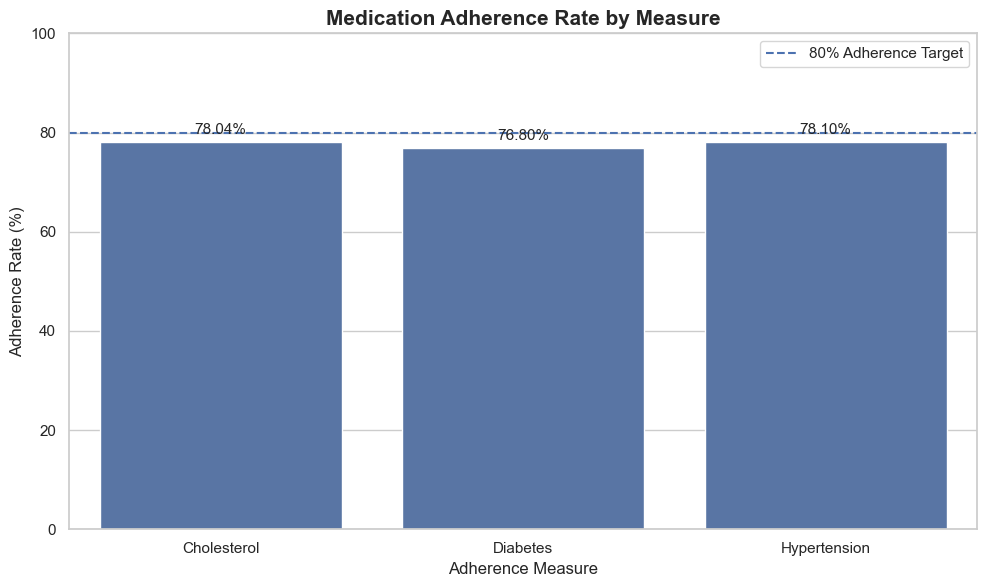

In [17]:

# ==========================================
# CHART 1: ADHERENCE RATE BY MEASURE
# ==========================================

plot_data = adherence_summary.copy()

# Make measure names easier to read

plot_data["measure_label"] = plot_data["measure"].replace({
    "cholesterol_statins": "Cholesterol",
    "diabetes": "Diabetes",
    "hypertension_ras": "Hypertension"
})

# Create the chart

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=plot_data,
    x="measure_label",
    y="adherence_rate",
    errorbar=None
)

# Add the 80% adherence threshold

plt.axhline(
    y=80,
    linestyle="--",
    label="80% Adherence Target"
)

# Add percentage labels above bars

for bar in ax.patches:

    height = bar.get_height()

    ax.annotate(
        f"{height:.2f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        xytext=(0, 6),
        textcoords="offset points"
    )

plt.title(
    "Medication Adherence Rate by Measure",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Adherence Measure")
plt.ylabel("Adherence Rate (%)")

plt.ylim(0, 100)

plt.legend()
plt.tight_layout()

plt.show()


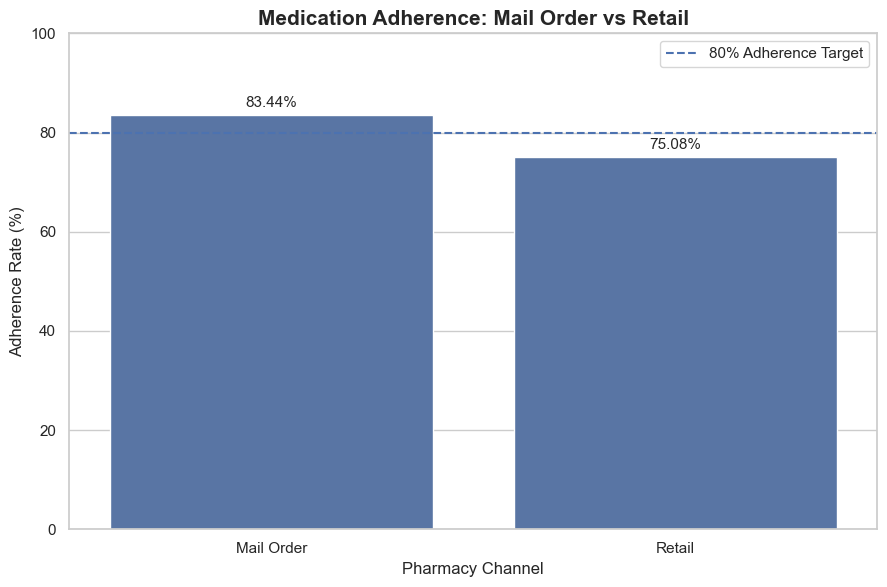

In [18]:

# ==========================================
# CHART 2: MAIL ORDER VS RETAIL
# ==========================================

plt.figure(figsize=(9, 6))

ax = sns.barplot(
    data=channel_adherence_summary,
    x="dominant_channel",
    y="adherence_rate",
    errorbar=None
)

# Add the 80% target line

plt.axhline(
    y=80,
    linestyle="--",
    label="80% Adherence Target"
)

# Add percentage labels

for bar in ax.patches:

    height = bar.get_height()

    ax.annotate(
        f"{height:.2f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        xytext=(0, 6),
        textcoords="offset points"
    )

plt.title(
    "Medication Adherence: Mail Order vs Retail",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Pharmacy Channel")
plt.ylabel("Adherence Rate (%)")

plt.ylim(0, 100)

plt.legend()
plt.tight_layout()

plt.show()


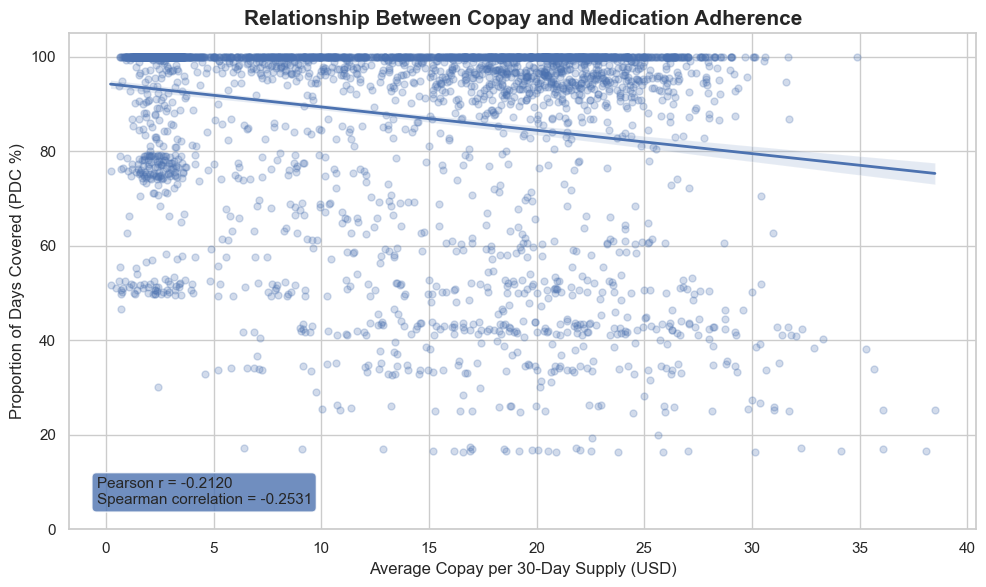

In [19]:

# ==========================================
# CHART 3: COPAY VS MEDICATION ADHERENCE
# ==========================================

# Prepare plotting data without patient identifiers

plot_copay = copay_adherence[
    ["average_copay_per_30_days", "pdc"]
].dropna().copy()

# Convert PDC into percentage

plot_copay["pdc_percentage"] = plot_copay["pdc"] * 100

# Calculate correlations for chart annotation

pearson_corr = plot_copay[
    "average_copay_per_30_days"
].corr(plot_copay["pdc_percentage"])

spearman_corr = (
    plot_copay["average_copay_per_30_days"].rank()
    .corr(plot_copay["pdc_percentage"].rank())
)

# Create scatter plot with regression line

plt.figure(figsize=(10, 6))

ax = sns.regplot(
    data=plot_copay,
    x="average_copay_per_30_days",
    y="pdc_percentage",
    scatter_kws={"alpha": 0.25, "s": 25},
    line_kws={"linewidth": 2},
    ci=95
)

# Add chart titles and labels

plt.title(
    "Relationship Between Copay and Medication Adherence",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Average Copay per 30-Day Supply (USD)")
plt.ylabel("Proportion of Days Covered (PDC %)")

plt.ylim(0, 105)

# Display correlation values

plt.text(
    0.03,
    0.05,
    f"Pearson r = {pearson_corr:.4f}\nSpearman correlation = {spearman_corr:.4f}",
    transform=ax.transAxes,
    bbox={"boxstyle": "round", "alpha": 0.8}
)

plt.tight_layout()
plt.show()


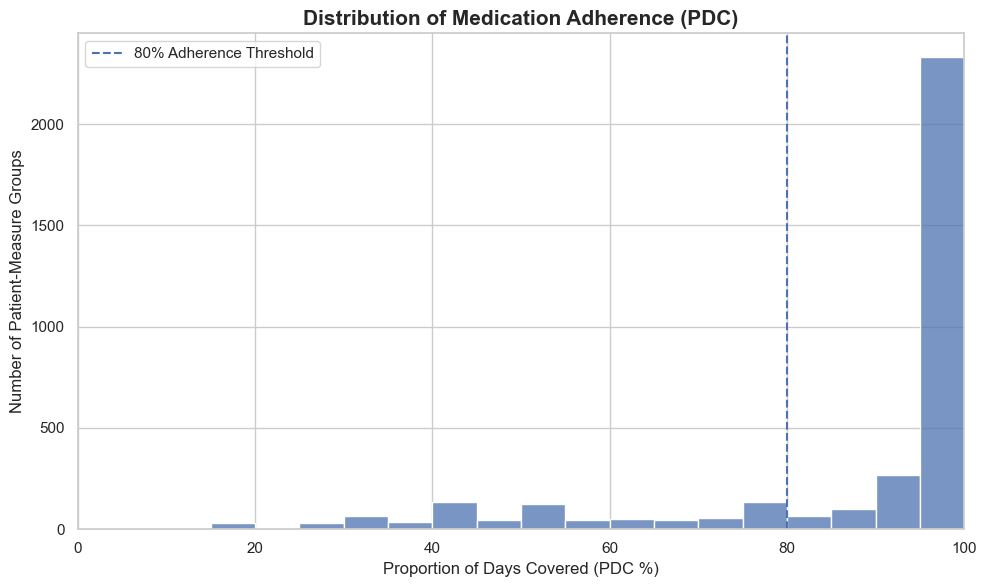

In [20]:

# ==========================================
# CHART 4: PDC DISTRIBUTION
# ==========================================

# Prepare PDC data as percentages

pdc_data = patient_adherence["pdc"].dropna() * 100

plt.figure(figsize=(10, 6))

# Create histogram

ax = sns.histplot(
    pdc_data,
    bins=np.arange(0, 105, 5),
    kde=False
)

# Add 80% adherence threshold

plt.axvline(
    x=80,
    linestyle="--",
    label="80% Adherence Threshold"
)

# Add chart title and labels

plt.title(
    "Distribution of Medication Adherence (PDC)",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Proportion of Days Covered (PDC %)")
plt.ylabel("Number of Patient-Measure Groups")

plt.xlim(0, 100)

plt.legend()
plt.tight_layout()

plt.show()


In [21]:

# ==========================================
# SAVE ALL FOUR VISUALIZATIONS
# ==========================================

from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Create figure output folder

figure_path = Path("../reports/figures")
figure_path.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")


# ------------------------------------------
# CHART 1: ADHERENCE BY MEASURE
# ------------------------------------------

plot_data = adherence_summary.copy()

plot_data["measure_label"] = plot_data["measure"].replace({
    "cholesterol_statins": "Cholesterol",
    "diabetes": "Diabetes",
    "hypertension_ras": "Hypertension"
})

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=plot_data,
    x="measure_label",
    y="adherence_rate",
    errorbar=None
)

plt.axhline(
    80,
    linestyle="--",
    label="80% Adherence Target"
)

for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{height:.2f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        xytext=(0, 6),
        textcoords="offset points"
    )

plt.title("Medication Adherence Rate by Measure")
plt.xlabel("Adherence Measure")
plt.ylabel("Adherence Rate (%)")
plt.ylim(0, 100)
plt.legend()
plt.tight_layout()

plt.savefig(
    figure_path / "01_adherence_by_measure.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close()


# ------------------------------------------
# CHART 2: MAIL ORDER VS RETAIL
# ------------------------------------------

plt.figure(figsize=(9, 6))

ax = sns.barplot(
    data=channel_adherence_summary,
    x="dominant_channel",
    y="adherence_rate",
    errorbar=None
)

plt.axhline(
    80,
    linestyle="--",
    label="80% Adherence Target"
)

for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{height:.2f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        xytext=(0, 6),
        textcoords="offset points"
    )

plt.title("Medication Adherence: Mail Order vs Retail")
plt.xlabel("Pharmacy Channel")
plt.ylabel("Adherence Rate (%)")
plt.ylim(0, 100)
plt.legend()
plt.tight_layout()

plt.savefig(
    figure_path / "02_mail_order_vs_retail.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close()


# ------------------------------------------
# CHART 3: COPAY VS PDC
# ------------------------------------------

plot_copay = copay_adherence[
    ["average_copay_per_30_days", "pdc"]
].dropna().copy()

plot_copay["pdc_percentage"] = plot_copay["pdc"] * 100

plt.figure(figsize=(10, 6))

ax = sns.regplot(
    data=plot_copay,
    x="average_copay_per_30_days",
    y="pdc_percentage",
    scatter_kws={"alpha": 0.25, "s": 25},
    line_kws={"linewidth": 2},
    ci=95
)

pearson_corr = plot_copay[
    "average_copay_per_30_days"
].corr(plot_copay["pdc_percentage"])

spearman_corr = (
    plot_copay["average_copay_per_30_days"].rank()
    .corr(plot_copay["pdc_percentage"].rank())
)

plt.title("Relationship Between Copay and Medication Adherence")
plt.xlabel("Average Copay per 30-Day Supply (USD)")
plt.ylabel("Proportion of Days Covered (PDC %)")

plt.ylim(0, 105)

plt.text(
    0.03,
    0.05,
    f"Pearson r = {pearson_corr:.4f}\nSpearman = {spearman_corr:.4f}",
    transform=ax.transAxes,
    bbox={"boxstyle": "round", "alpha": 0.8}
)

plt.tight_layout()

plt.savefig(
    figure_path / "03_copay_vs_pdc.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close()


# ------------------------------------------
# CHART 4: PDC DISTRIBUTION
# ------------------------------------------

pdc_data = patient_adherence["pdc"].dropna() * 100

plt.figure(figsize=(10, 6))

sns.histplot(
    pdc_data,
    bins=np.arange(0, 105, 5)
)

plt.axvline(
    80,
    linestyle="--",
    label="80% Adherence Threshold"
)

plt.title("Distribution of Medication Adherence (PDC)")
plt.xlabel("Proportion of Days Covered (PDC %)")
plt.ylabel("Number of Patient-Measure Groups")
plt.xlim(0, 100)
plt.legend()
plt.tight_layout()

plt.savefig(
    figure_path / "04_pdc_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close()


# ------------------------------------------
# VERIFY EXPORTED CHARTS
# ------------------------------------------

saved_figures = list(figure_path.glob("*.png"))

print("VISUALIZATION EXPORT COMPLETED!")
print("=" * 45)

for file in saved_figures:
    print(file.name, "— SAVED")

print("\nTotal visualizations saved:", len(saved_figures))


VISUALIZATION EXPORT COMPLETED!
01_adherence_by_measure.png — SAVED
02_mail_order_vs_retail.png — SAVED
03_copay_vs_pdc.png — SAVED
04_pdc_distribution.png — SAVED

Total visualizations saved: 4
